# 1. Przygotowanie danych do analizy

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

/root/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/root/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
pd.set_option('display.max_columns', None) # pokaż wszystkie kolumny
sns.set(style="whitegrid")

In [3]:
df = pd.read_csv("pimaDataset.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [6]:
print(f"Wiersze: {df.shape[0]}, kolumny: {df.shape[1]}")

Wiersze: 768, kolumny 9


# 2. Wstępna Analiza

Sprawdzenie, czy są wartości null:

In [9]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [13]:
df.duplicated().sum()

0

In [7]:
df.describe(

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Correlation matrix:


<AxesSubplot:>

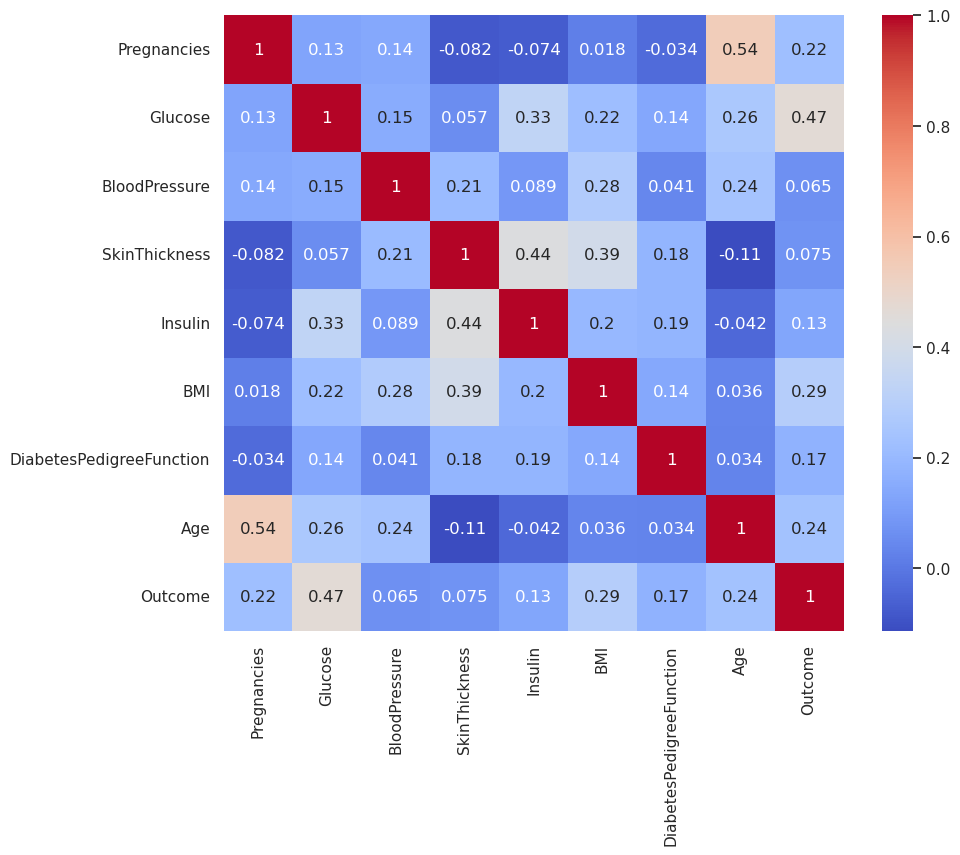

In [12]:
print("\nCorrelation matrix:")
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True,cmap='coolwarm')

In [18]:
df[ (df["Glucose"] == 0) | (df["BloodPressure"] == 0) | (df["SkinThickness"] == 0) | (df["Insulin"] == 0) | (df["BMI"] == 0) ]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
5,5,116,74,0,0,25.6,0.201,30,0
7,10,115,0,0,0,35.3,0.134,29,0
...,...,...,...,...,...,...,...,...,...
761,9,170,74,31,0,44.0,0.403,43,1
762,9,89,62,0,0,22.5,0.142,33,0
764,2,122,70,27,0,36.8,0.340,27,0
766,1,126,60,0,0,30.1,0.349,47,1


Wartości dla glukozy, ciśnienia krwi, insuliny, grubości skóry i BMI powinny być różne od 0

AttributeError: 'numpy.ndarray' object has no attribute 'xaxis'

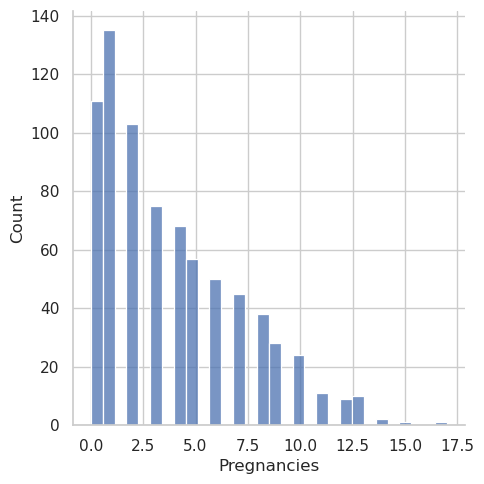

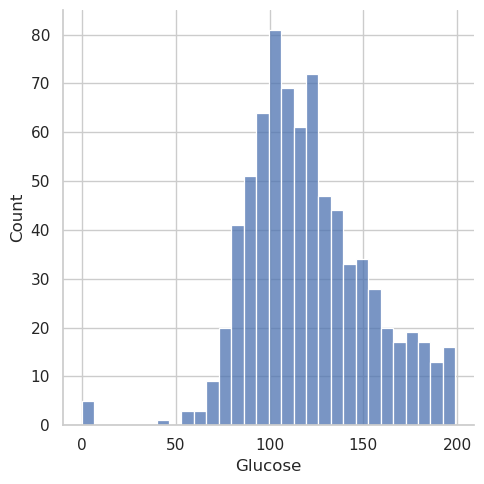

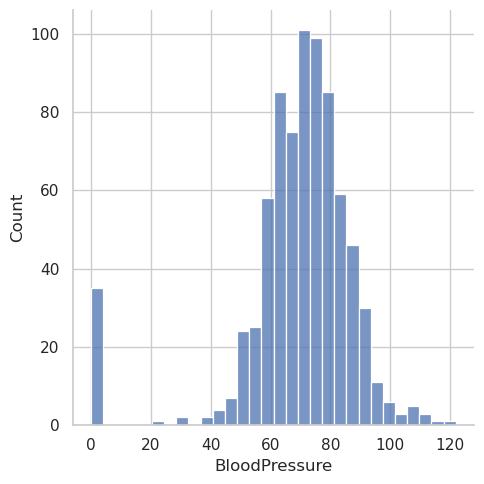

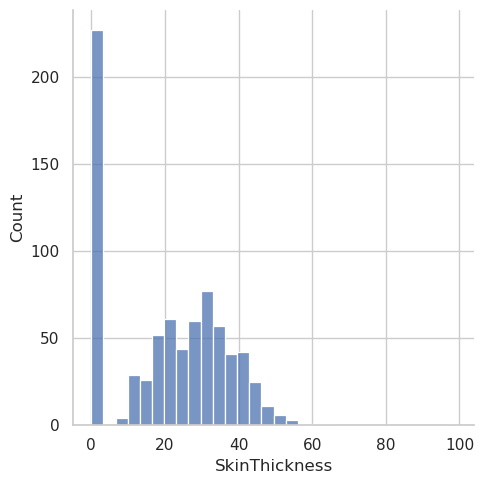

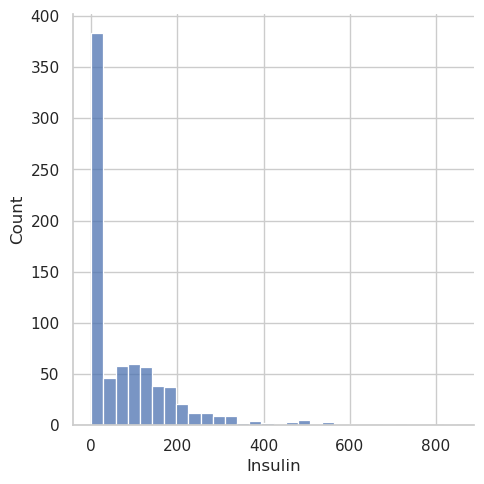

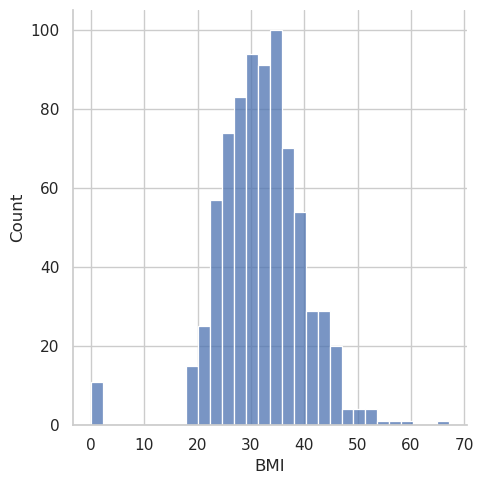

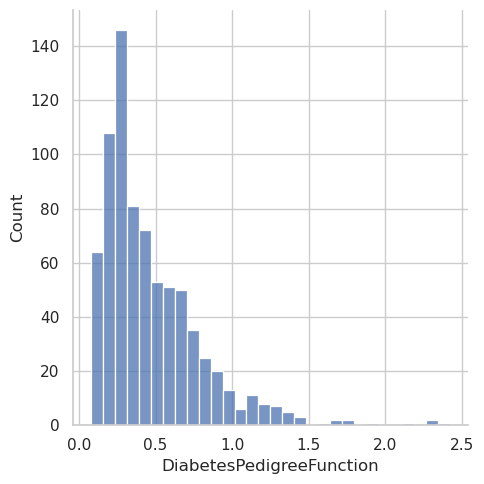

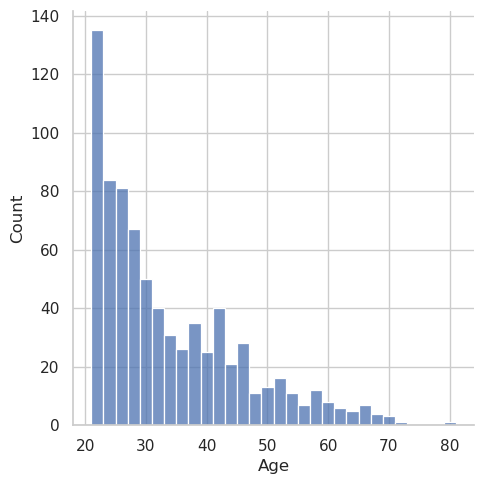

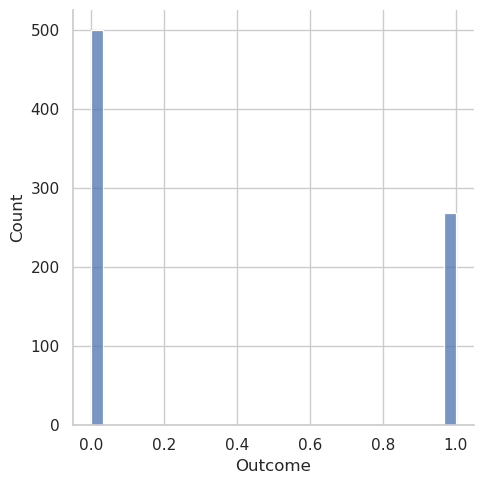

In [86]:
for col in df.columns:
    sns.displot(df[col], kde=False,bins=30)

cols = 2  # number of columns in the grid
rows = (len(df.columns) + cols - 1) // cols  # number of rows needed
# fig, axes = plt.subplots(nrows=rows, ncols=cols)
# plt.figure(figsize=(5 * cols, 4 * rows))

# Create seaborn plots in each subplot
for i, col in enumerate(df.columns):
    sns.histplot(data=df, x=col, bins=30, kde=False, color='skyblue', ax=axes[i])
    axes[i].set_title(col)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])


plt.suptitle("Distributions of Features", fontsize=20)
plt.subplots_adjust(top=0.93)
plt.show()


# Uzupełnianie braków danych

Mamy 376 wierszy z brakującymi wartościami

In [31]:
df2 = df.copy()
df2[["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]] = df2[["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]].replace(0, np.nan)
df2.isna().sum() /len(df2)

Pregnancies                 0.000000
Glucose                     0.006510
BloodPressure               0.045573
SkinThickness               0.295573
Insulin                     0.486979
BMI                         0.014323
DiabetesPedigreeFunction    0.000000
Age                         0.000000
Outcome                     0.000000
dtype: float64

<AxesSubplot:>

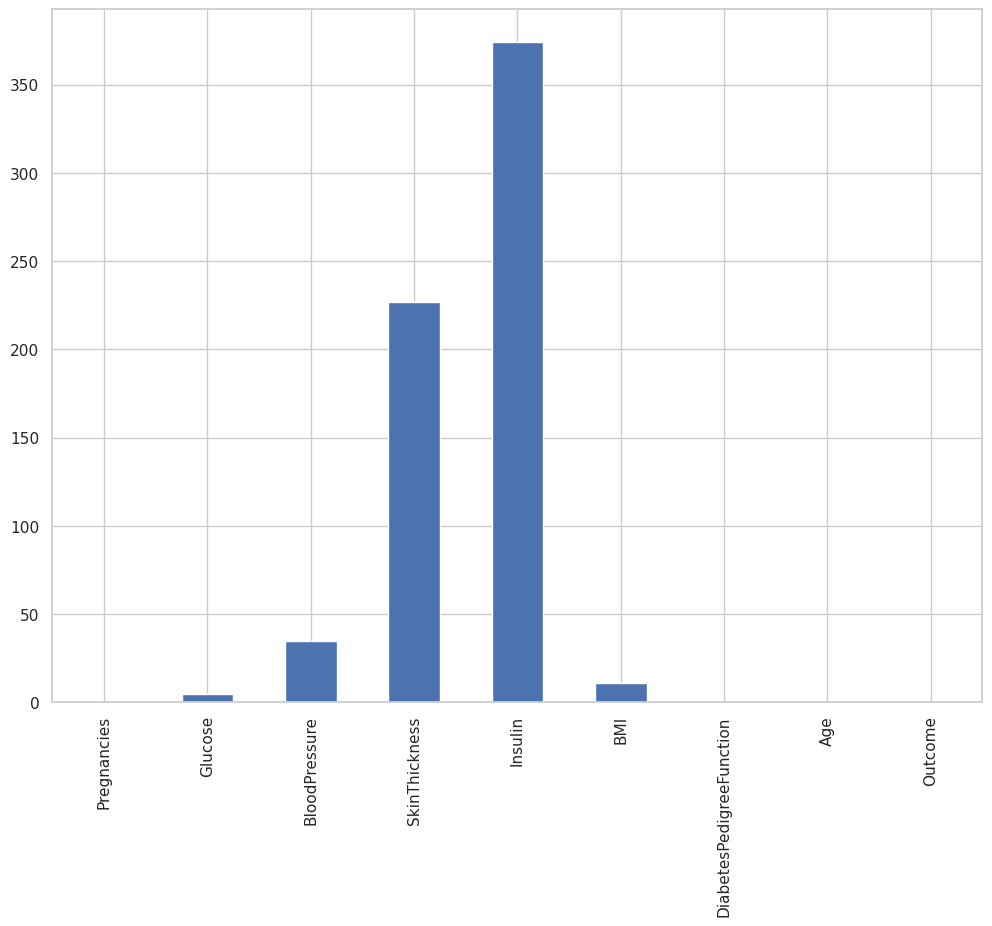

In [32]:
df2.isna().sum().plot(kind='bar', figsize=(12,9))

<AxesSubplot:>

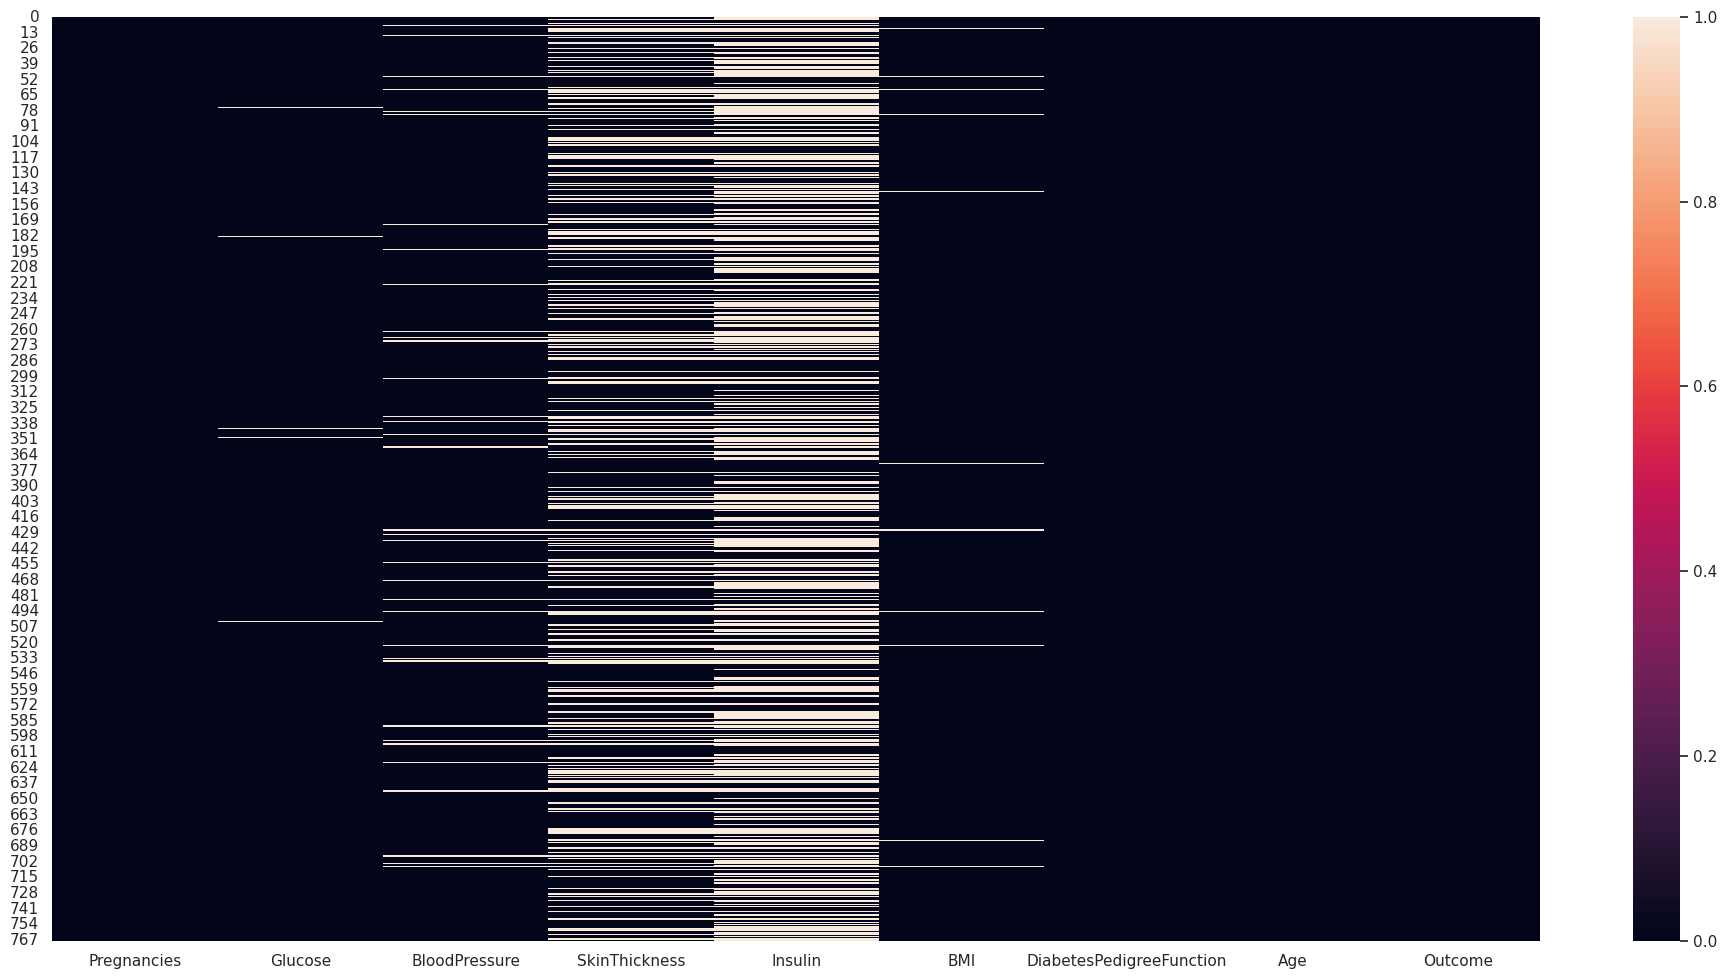

In [33]:
plt.figure(figsize=(24,12))
sns.heatmap(df2.isna())

In [39]:
df2[df2["Insulin"].isna()].describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,374.000000,370.000000,339.000000,147.000000,0.0,364.000000,374.000000,374.000000,374.000000
mean,4.433155,120.700000,74.439528,29.278912,NaN,31.793407,0.415340,35.796791,0.368984
std,3.437621,30.238604,11.979706,10.438195,NaN,6.763519,0.300547,12.729034,0.483176
min,0.000000,44.000000,44.000000,8.000000,NaN,18.200000,0.078000,21.000000,0.000000
25%,1.000000,100.250000,66.000000,22.000000,NaN,26.800000,0.209000,25.000000,0.000000
50%,4.000000,115.000000,74.000000,30.000000,NaN,31.200000,0.302500,32.000000,0.000000
75%,7.000000,138.000000,82.000000,35.500000,NaN,35.725000,0.553250,43.000000,1.000000
max,14.000000,199.000000,122.000000,99.000000,NaN,52.900000,1.893000,72.000000,1.000000


In [37]:
df2[df2["SkinThickness"].isna()].describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,227.000000,227.000000,194.000000,0.0,0.0,218.000000,227.000000,227.000000,227.000000
mean,4.638767,123.449339,75.025773,NaN,NaN,31.373853,0.393291,37.251101,0.387665
std,3.350062,29.572931,12.305454,NaN,NaN,6.952505,0.276871,13.062933,0.488294
min,0.000000,44.000000,48.000000,NaN,NaN,18.200000,0.078000,21.000000,0.000000
25%,2.000000,105.000000,66.000000,NaN,NaN,25.925000,0.203000,27.000000,0.000000
50%,4.000000,120.000000,74.500000,NaN,NaN,30.850000,0.282000,34.000000,0.000000
75%,7.000000,140.500000,82.000000,NaN,NaN,35.300000,0.536500,45.000000,1.000000
max,13.000000,197.000000,122.000000,NaN,NaN,52.900000,1.781000,72.000000,1.000000


In [40]:
df2[df2["Outcome"] == 0 ].describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,500.000000,497.000000,481.000000,361.000000,264.000000,491.000000,500.000000,500.000000,500.0
mean,3.298000,110.643863,70.877339,27.235457,130.287879,30.859674,0.429734,31.190000,0.0
std,3.017185,24.776906,12.161223,10.026491,102.482237,6.560737,0.299085,11.667655,0.0
min,0.000000,44.000000,24.000000,7.000000,15.000000,18.200000,0.078000,21.000000,0.0
25%,1.000000,93.000000,62.000000,19.000000,66.000000,25.600000,0.229750,23.000000,0.0
50%,2.000000,107.000000,70.000000,27.000000,102.500000,30.100000,0.336000,27.000000,0.0
75%,5.000000,125.000000,78.000000,33.000000,161.250000,35.300000,0.561750,37.000000,0.0
max,13.000000,197.000000,122.000000,60.000000,744.000000,57.300000,2.329000,81.000000,0.0


In [41]:
df2[df2["Outcome"] == 1 ].describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,268.000000,266.000000,252.000000,180.000000,130.000000,266.000000,268.000000,268.000000,268.0
mean,4.865672,142.319549,75.321429,33.000000,206.846154,35.406767,0.550500,37.067164,1.0
std,3.741239,29.599199,12.299866,10.327595,132.699898,6.614982,0.372354,10.968254,0.0
min,0.000000,78.000000,30.000000,7.000000,14.000000,22.900000,0.088000,21.000000,1.0
25%,1.750000,119.000000,68.000000,27.000000,127.500000,30.900000,0.262500,28.000000,1.0
50%,4.000000,140.000000,74.500000,32.000000,169.500000,34.300000,0.449000,36.000000,1.0
75%,8.000000,167.000000,84.000000,39.000000,239.250000,38.925000,0.728000,44.000000,1.0
max,17.000000,199.000000,114.000000,99.000000,846.000000,67.100000,2.420000,70.000000,1.0


# Imputacja brakujących danych metodą KNN

In [44]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, IterativeImputer
imputer = KNNImputer(n_neighbors=5)
df_imputed = df2.copy()
features = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
df_imputed.loc[:,features]=imputer.fit_transform(df_imputed[features])

In [45]:
df_imputed.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.748698,72.348958,28.887240,150.321615,32.453021,0.471876,33.240885,0.348958
std,3.369578,30.463612,12.194234,9.491386,98.520049,6.883921,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,22.000000,85.450000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,28.800000,129.300000,32.300000,0.372500,29.000000,0.000000
75%,6.000000,141.000000,80.000000,35.000000,188.500000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Correlation matrix:


<AxesSubplot:>

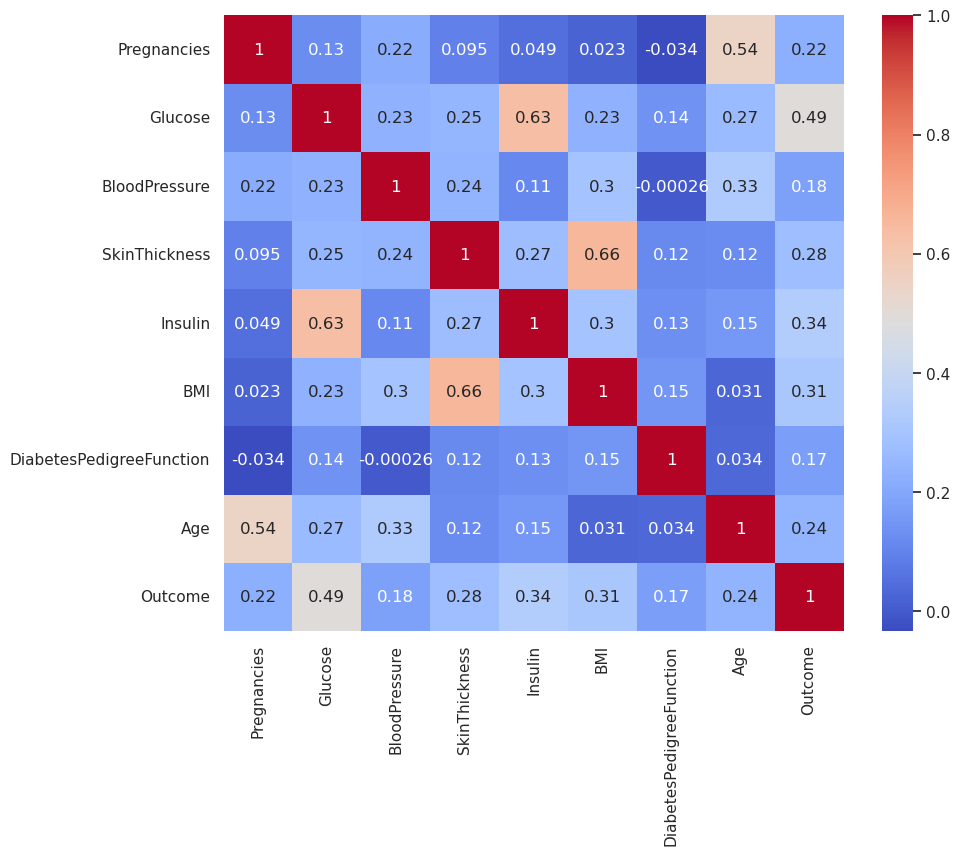

In [46]:
print("\nCorrelation matrix:")
plt.figure(figsize=(10, 8))
sns.heatmap(df_imputed.corr(), annot=True,cmap='coolwarm')

5. Które zmienne najsilniej różnicują osoby chore i zdrowe?
Hipoteza: Istnieją cechy fizjologiczne, które w większym stopniu niż inne wskazują na ryzyko cukrzycy.

Podpunkty:

Jakie są wartości korelacji między Outcome a innymi zmiennymi?

Jakie zmienne mają największą różnicę średnich pomiędzy grupami?

Które zmienne (np. glukoza, BMI, wiek) mają największą wartość predykcyjną?

Jak wizualizacje (np. boxploty, heatmapy korelacji) wspierają te obserwacje?

<AxesSubplot:xlabel='Pregnancies', ylabel='Density'>

<AxesSubplot:xlabel='Glucose', ylabel='Density'>

<AxesSubplot:xlabel='BloodPressure', ylabel='Density'>

<AxesSubplot:xlabel='SkinThickness', ylabel='Density'>

<AxesSubplot:xlabel='Insulin', ylabel='Density'>

<AxesSubplot:xlabel='BMI', ylabel='Density'>

<AxesSubplot:xlabel='DiabetesPedigreeFunction', ylabel='Density'>

<AxesSubplot:xlabel='Age', ylabel='Density'>

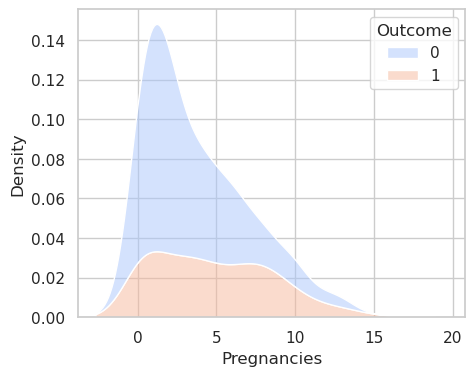

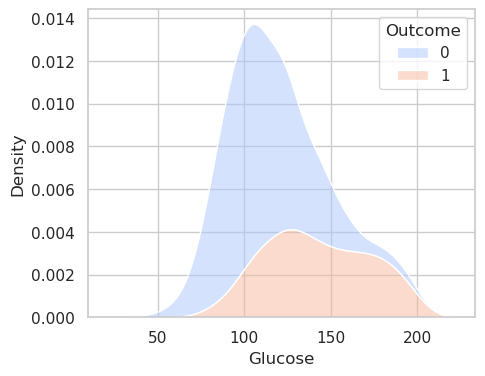

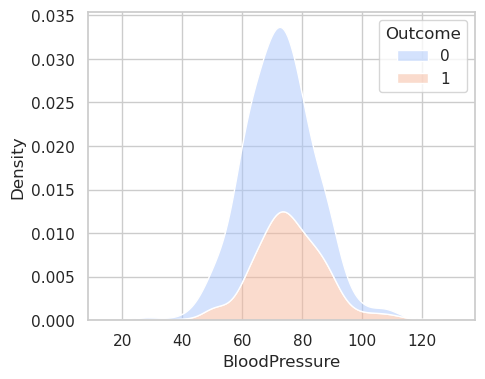

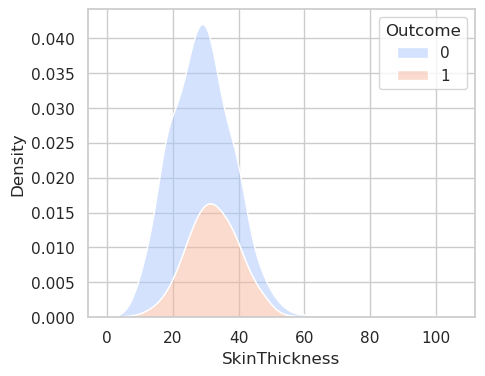

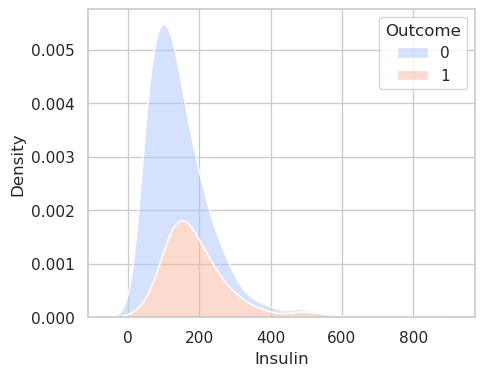

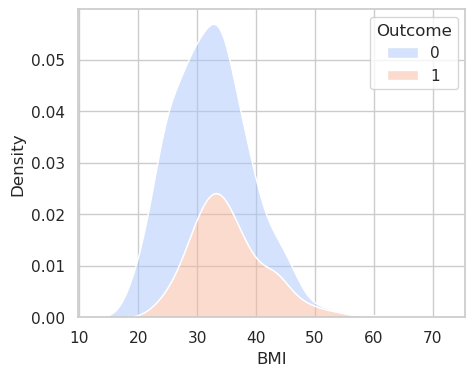

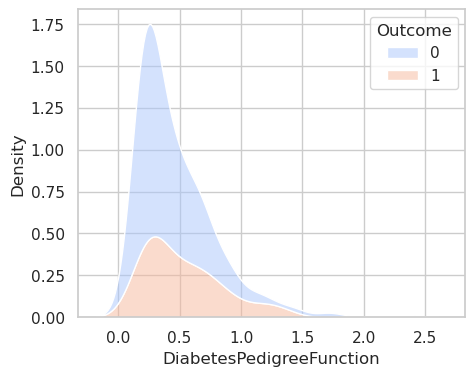

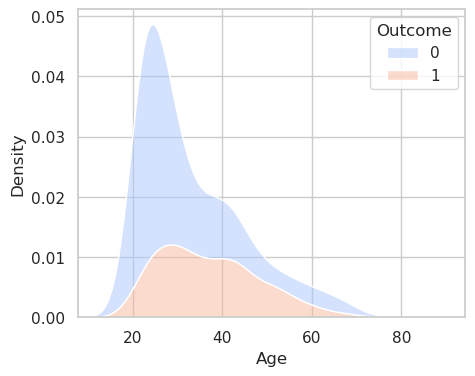

In [57]:
for col in ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age']:
    plt.figure(figsize=(5, 4))
    display(sns.kdeplot(data=df_imputed, x=col, hue="Outcome", multiple="stack", alpha=0.5, palette='coolwarm'))

Spróbujmy znormalizować dane:

In [69]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
np_scalled = scaler.fit_transform(X = df_imputed[['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age']], y = df_imputed["Outcome"])


In [73]:
df_scalled = pd.DataFrame(data=np_scalled, columns=['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'])
df_scalled["Outcome"] = df_imputed["Outcome"]

<AxesSubplot:xlabel='Pregnancies', ylabel='Density'>

<AxesSubplot:xlabel='Glucose', ylabel='Density'>

<AxesSubplot:xlabel='BloodPressure', ylabel='Density'>

<AxesSubplot:xlabel='SkinThickness', ylabel='Density'>

<AxesSubplot:xlabel='Insulin', ylabel='Density'>

<AxesSubplot:xlabel='BMI', ylabel='Density'>

<AxesSubplot:xlabel='DiabetesPedigreeFunction', ylabel='Density'>

<AxesSubplot:xlabel='Age', ylabel='Density'>

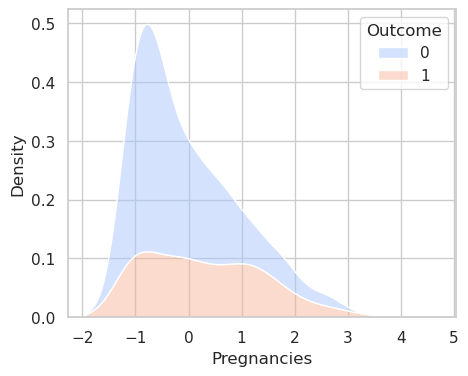

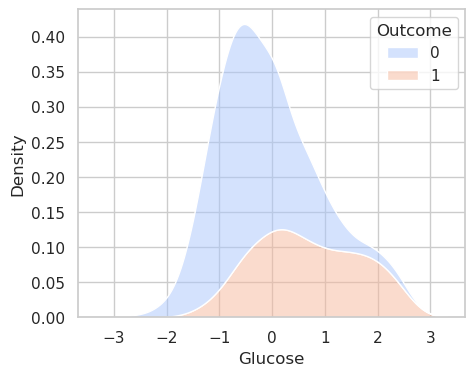

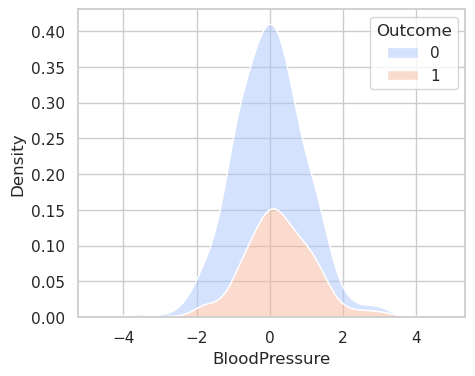

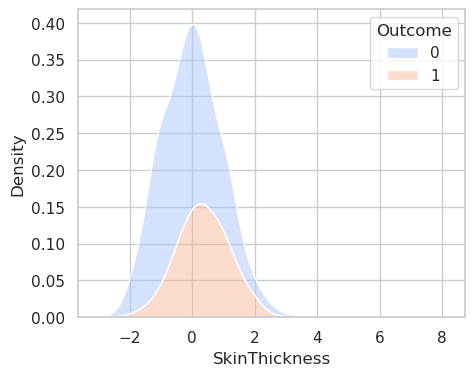

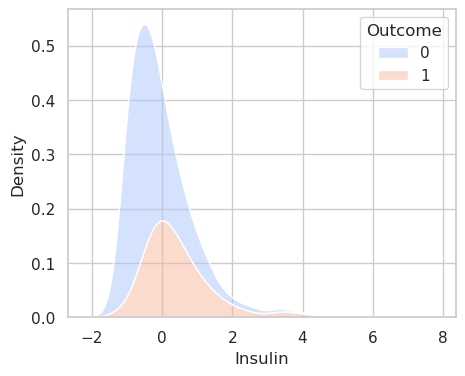

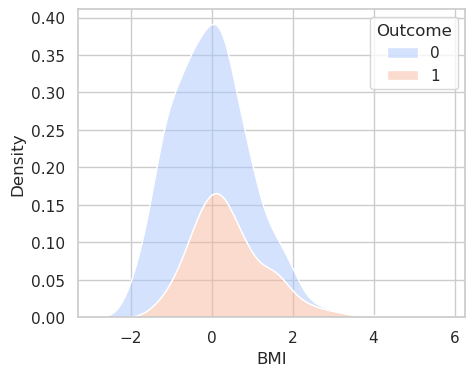

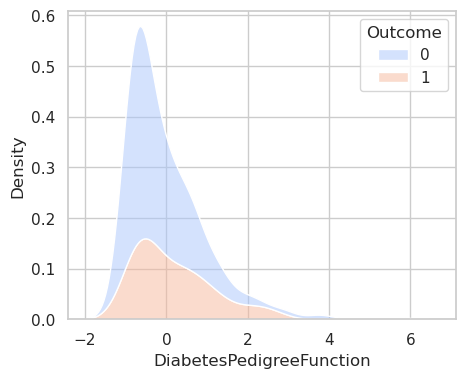

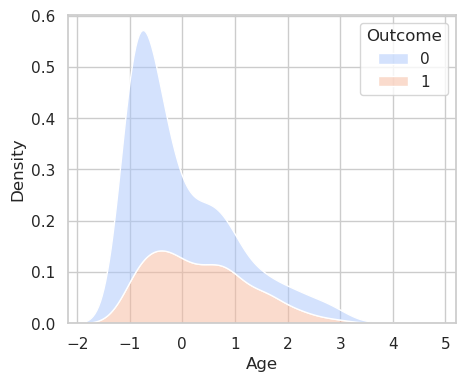

In [74]:
for col in ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age']:
    plt.figure(figsize=(5, 4))
    display(sns.kdeplot(data=df_scalled, x=col, hue="Outcome", multiple="stack", alpha=0.5, palette='coolwarm'))

In [93]:
df_imputed.corr().sort_values(by="Outcome")

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
DiabetesPedigreeFunction,-0.033523,0.136860,-0.000262,0.119837,0.131794,0.152134,1.000000,0.033561,0.173844
BloodPressure,0.215428,0.231934,1.000000,0.240791,0.112299,0.297395,-0.000262,0.326810,0.177829
Pregnancies,1.000000,0.126862,0.215428,0.094821,0.049211,0.022979,-0.033523,0.544341,0.221898
Age,0.544341,0.265111,0.326810,0.121907,0.153443,0.030702,0.033561,1.000000,0.238356
SkinThickness,0.094821,0.246306,0.240791,1.000000,0.270635,0.658912,0.119837,0.121907,0.276664
BMI,0.022979,0.233029,0.297395,0.658912,0.296331,1.000000,0.152134,0.030702,0.312216
Insulin,0.049211,0.633321,0.112299,0.270635,1.000000,0.296331,0.131794,0.153443,0.336613
Glucose,0.126862,1.000000,0.231934,0.246306,0.633321,0.233029,0.136860,0.265111,0.492195
Outcome,0.221898,0.492195,0.177829,0.276664,0.336613,0.312216,0.173844,0.238356,1.000000


In [94]:
df_imputed.groupby(["Outcome"]).mean()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,3.298000,110.778400,70.762400,26.966000,126.058000,30.880520,0.429734,31.190000
1,4.865672,142.215672,75.308955,32.471642,195.589552,35.386791,0.550500,37.067164


In [102]:
df_scalled.groupby(["Outcome"]).mean()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,-0.162456,-0.360346,-0.130192,-0.202551,-0.246441,-0.228580,-0.127275,-0.174505
1,0.303090,0.672288,0.242896,0.377894,0.459779,0.426455,0.237453,0.325569


## Jakie zmienne mają największą różnicę średnich pomiędzy grupami?

In [110]:
by_outcome_mean = df_scalled.groupby(["Outcome"]).mean()
(by_outcome_mean.loc[1] - by_outcome_mean.loc[0]).sort_values(ascending=False)


Glucose                     1.032634
Insulin                     0.706220
BMI                         0.655035
SkinThickness               0.580445
Age                         0.500075
Pregnancies                 0.465546
BloodPressure               0.373088
DiabetesPedigreeFunction    0.364728
dtype: float64

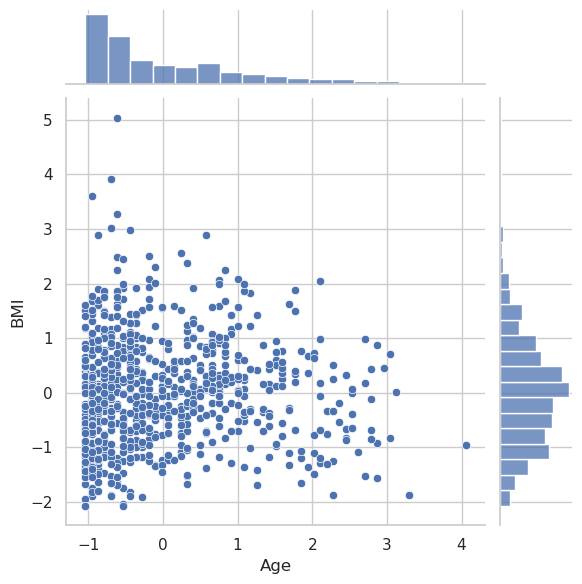

In [112]:
sns.jointplot(x='Age', y='BMI', data=df_scalled, kind='scatter', palette='coolwarm')


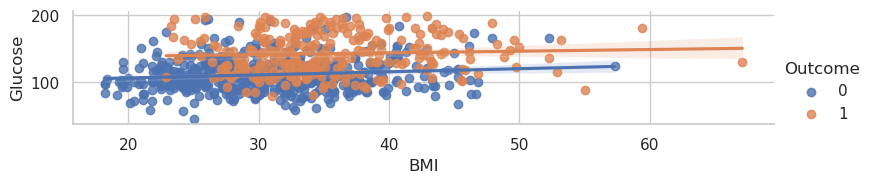

In [113]:
sns.lmplot(x='BMI',y='Glucose', hue='Outcome',height=2,aspect=4,data=df_imputed)

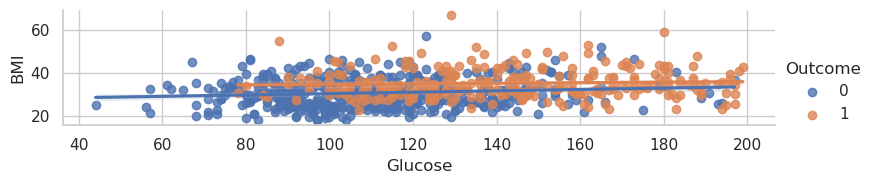

In [114]:
sns.lmplot(x='Glucose',y='BMI', hue='Outcome',height=2,aspect=4,data=df_imputed)

<AxesSubplot:xlabel='BMI_category', ylabel='Glucose'>

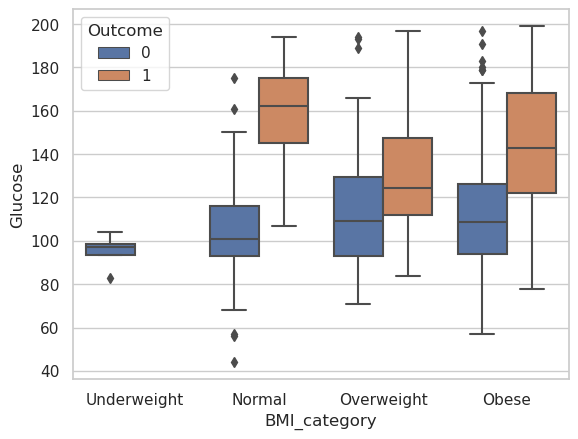

In [115]:
df_imputed['BMI_category'] = pd.cut(df_imputed['BMI'], bins=[0, 18.5, 25, 30, 100], labels=['Underweight', 'Normal', 'Overweight', 'Obese'])
sns.boxplot(x = "BMI_category", y = "Glucose", hue="Outcome", data = df_imputed)


<AxesSubplot:xlabel='BMI_category', ylabel='Glucose'>

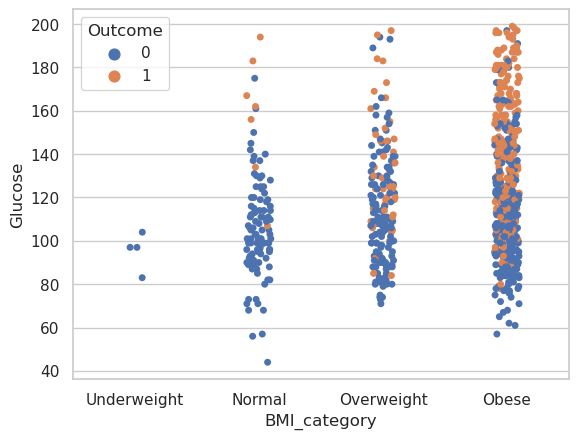

In [120]:
sns.stripplot(x = "BMI_category", y = "Glucose", hue="Outcome", data = df_imputed)


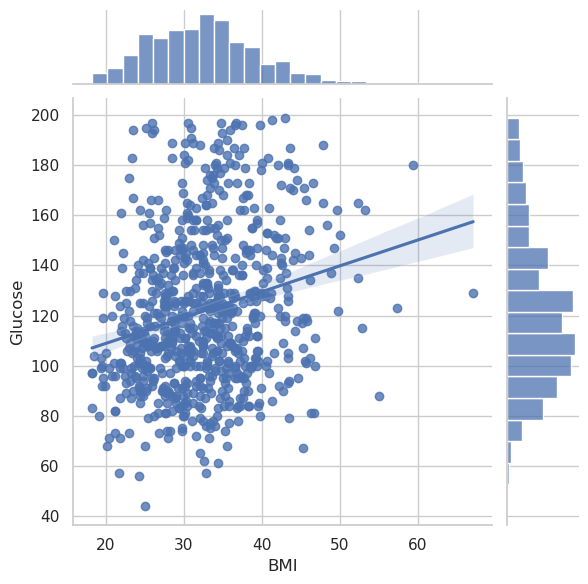

In [121]:
g = sns.JointGrid(x="BMI", y="Glucose", data=df_imputed)
g = g.plot(sns.regplot, sns.histplot)

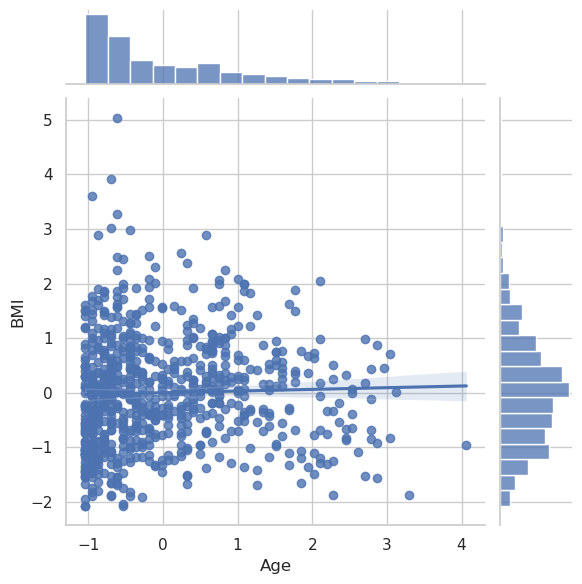

In [130]:
g = sns.JointGrid(x="Age", y="BMI", data=df_scalled)
g = g.plot(sns.regplot, sns.histplot)

In [ ]:
sns.swarmplot()

<AxesSubplot:xlabel='BMI_category', ylabel='Glucose'>

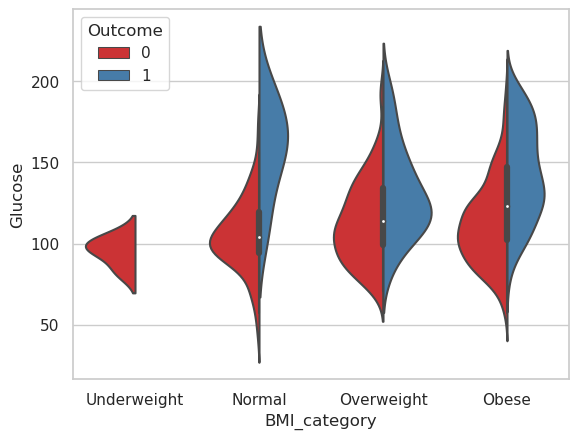

In [123]:
sns.violinplot(x="BMI_category", y="Glucose", data=df_imputed,hue='Outcome',split=True,palette='Set1')

<AxesSubplot:xlabel='BMI_category', ylabel='Insulin'>

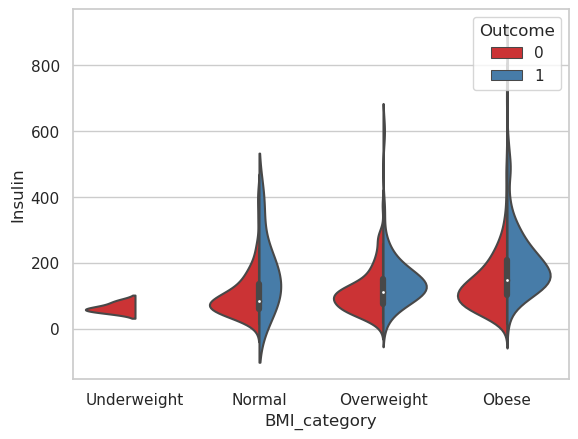

In [124]:
sns.violinplot(x="BMI_category", y="Insulin", data=df_imputed,hue='Outcome',split=True,palette='Set1')

In [125]:
df_imputed['Glucose_level'] = pd.qcut(df_imputed['Glucose'], q=3, labels=['Low', 'Medium', 'High'])


<AxesSubplot:xlabel='Glucose_level', ylabel='Insulin'>

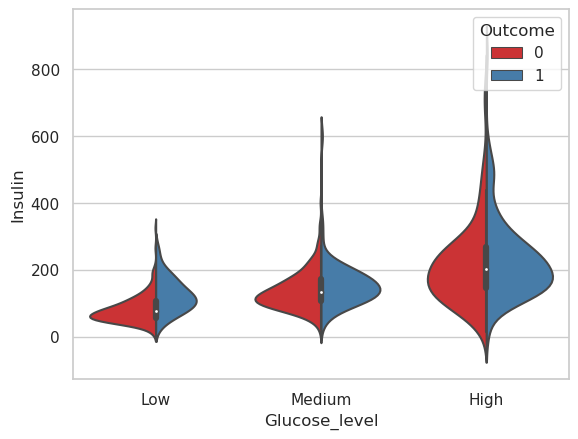

In [126]:
sns.violinplot(x="Glucose_level", y="Insulin", data=df_imputed,hue='Outcome',split=True,palette='Set1')

In [131]:
df_imputed['Age_group'] = pd.cut(df_imputed['Age'], bins=[20, 30, 40, 50, 60, 100], labels=['20–30', '31–40', '41–50', '51–60', '60+'])


<AxesSubplot:xlabel='Age_group', ylabel='Glucose'>

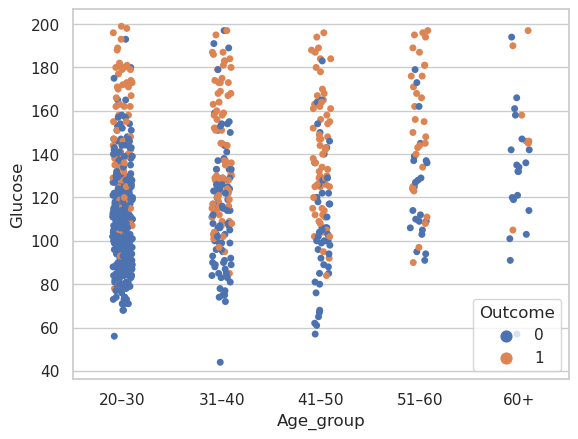

In [134]:
sns.stripplot(x = "Age_group", y = "Glucose", hue="Outcome", data=df_imputed)

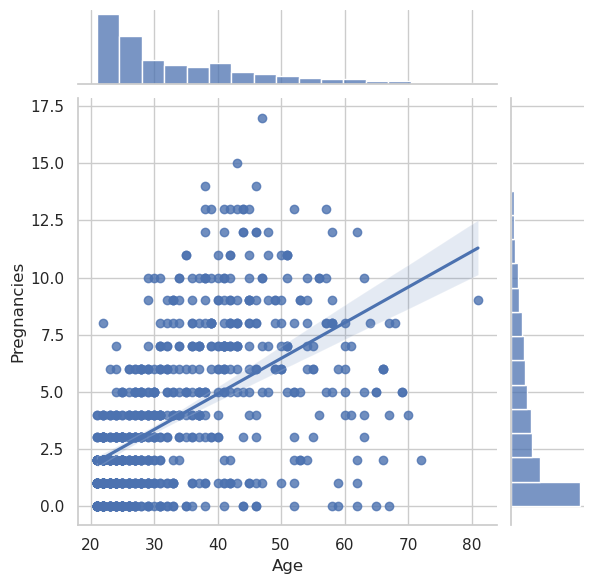

In [136]:
g = sns.JointGrid(x="Age", y="Pregnancies", data=df_imputed)
g.plot(sns.regplot, sns.histplot)

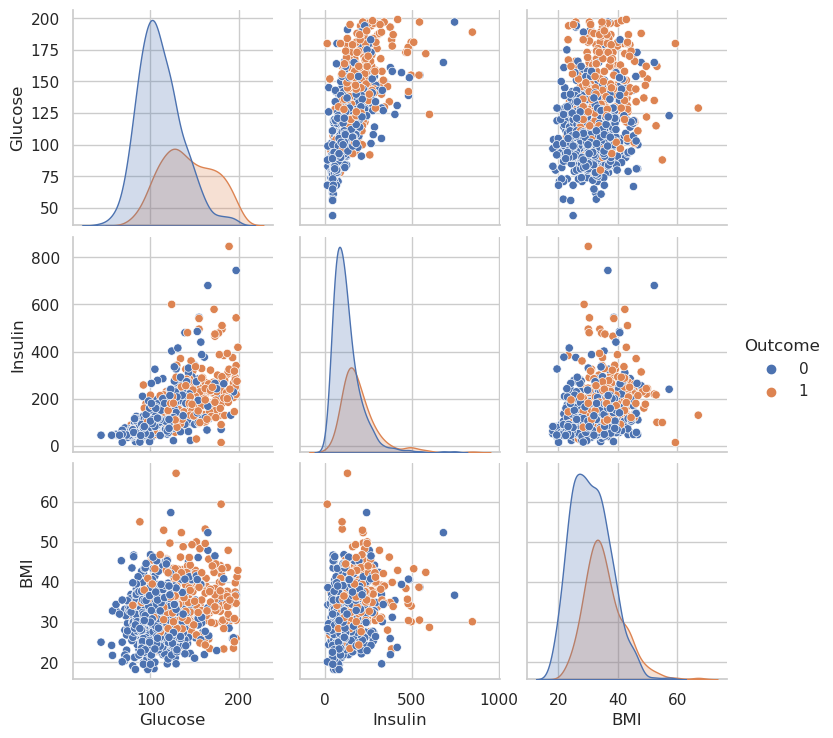

In [142]:
# sns.pairplot(df_imputed[["Glucose", "Insulin", "BMI", "SkinThickness", "Outcome", "Age"]],hue='Outcome')
sns.pairplot(df_imputed[["Glucose", "Insulin", "BMI", "Outcome"]], hue='Outcome')
